<a href="https://colab.research.google.com/github/OlgaLG-hub/EDA_World_happiness/blob/main/28_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Felicidad Mundial
Este cuaderno contiene un estudio simplificado y estructurado sobre la relación entre el nivel de felicidad (`Life Ladder`), el Producto Interno Bruto (`Log GDP per capita`) y el apoyo social (`Social support`). Cada paso se explica detalladamente a continuación.

### Paso 1: Carga y Vista Rápida de los Datos
En este primer paso, importamos las bibliotecas necesarias (`pandas`, `matplotlib`, `seaborn`) para el manejo y visualización de datos. Luego, cargamos el archivo CSV y mostramos las primeras filas junto con la información estructural del conjunto de datos.

In [197]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("World_2024.csv", encoding='latin1')

# Muestra las primeras cinco filas por defecto; no selecciona al azar.
display(df.head())

# Muestra tipos y valores no nulos por columna.
df.info()

,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.724,7.350,0.451,50.5,0.718,0.164,0.882,0.414,0.258
1,Afghanistan,2009,4.402,7.509,0.552,50.8,0.679,0.187,0.850,0.481,0.237
2,Afghanistan,2010,4.758,7.614,0.539,51.1,0.600,0.118,0.707,0.517,0.275
3,Afghanistan,2011,3.832,7.581,0.521,51.4,0.496,0.160,0.731,0.480,0.267
4,Afghanistan,2012,3.783,7.661,0.521,51.7,0.531,0.234,0.776,0.614,0.268


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2363 entries, 0 to 2362
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country name                      2363 non-null   object 
 1   year                              2363 non-null   int64  
 2   Life Ladder                       2363 non-null   float64
 3   Log GDP per capita                2335 non-null   float64
 4   Social support                    2350 non-null   float64
 5   Healthy life expectancy at birth  2300 non-null   float64
 6   Freedom to make life choices      2327 non-null   float64
 7   Generosity                        2282 non-null   float64
 8   Perceptions of corruption         2238 non-null   float64
 9   Positive affect                   2339 non-null   float64
 10  Negative affect                   2347 non-null   float64
dtypes: float64(9), int64(1), object(1)
memory usage: 203.2+ KB


### Paso 2: Limpieza de Datos y Análisis de Correlaciones
Seleccionamos las columnas clave (`Life Ladder`, `Log GDP per capita`, `Social support`) y eliminamos cualquier fila que contenga valores vacíos (nulos). Calculamos la matriz de correlación para evaluar la fuerza y dirección de las relaciones estadísticas con el nivel de felicidad.

In [198]:
# Lista de nombres de las columnas que se van a estudiar.
variables = ["Life Ladder", "Log GDP per capita", "Social support"]
# Selecciona las tres variables y descarta filas con algún ausente entre ellas.
datos = df[variables].dropna()

# len cuenta elementos o filas
print("Filas originales:", len(df))

print("Filas después de la limpieza:", len(datos))

# len cuenta elementos o filas; restar los tamaños permite contar las filas descartadas.
print("Filas eliminadas:", len(df[variables]) - len(datos))

# Calcula la matriz de correlación lineal de Pearson entre las columnas.
correlaciones = datos.corr()
# Muestra el objeto con el formato enriquecido del notebook.
display(correlaciones)


print("\nCorrelación con el nivel de felicidad (Life Ladder):")
print(correlaciones["Life Ladder"].round(3))

Filas originales: 2363
Filas después de la limpieza: 2322
Filas eliminadas: 41


,Life Ladder,Log GDP per capita,Social support
Life Ladder,1.000000,0.783036,0.719793
Log GDP per capita,0.783036,1.000000,0.685329
Social support,0.719793,0.685329,1.000000



Correlación con el nivel de felicidad (Life Ladder):
Life Ladder           1.000
Log GDP per capita    0.783
Social support        0.720
Name: Life Ladder, dtype: float64


### Paso 3: Visualización de Relaciones
Generamos tres gráficos en una sola fila utilizando subplots:
1. Un mapa de calor (heatmap) para visualizar de forma rápida la matriz de correlación.
2. Un gráfico de dispersión (scatter plot) que muestra la relación entre la felicidad y el PIB per cápita.
3. Un gráfico de dispersión para analizar la felicidad en relación con el nivel de apoyo social de las personas.

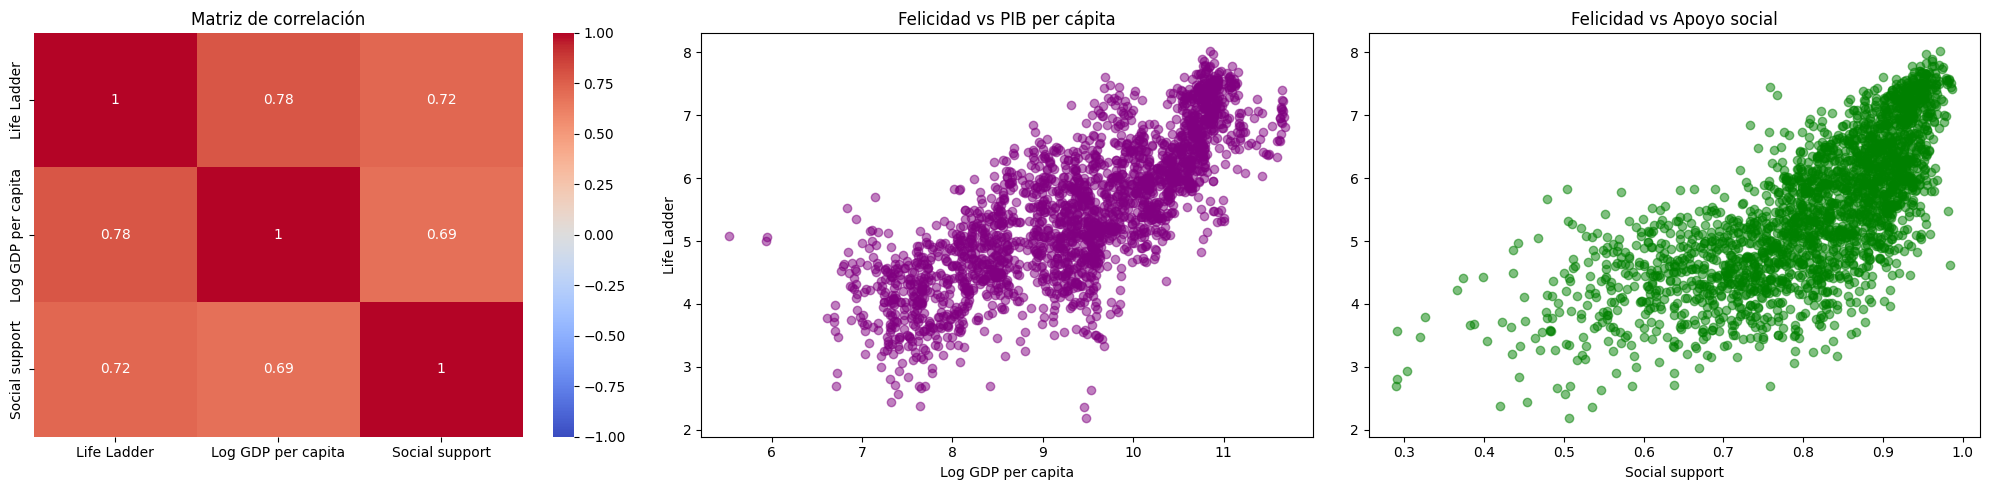

In [199]:

# Crea una figura con 1 fila y 3 gráficos; axes[0], axes[1] y axes[2] son sus ejes.
fig, axes = plt.subplots(1, 3, figsize=(20, 5))


# Representa la matriz con colores; annot imprime cifras y vmin/vmax fijan la escala.
sns.heatmap(correlaciones, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])

# Añade el título al subgráfico seleccionado.
axes[0].set_title("Matriz de correlación")

# Dibuja puntos segundo grafico: primero se pasa la variable X y después la Y.
axes[1].scatter(datos["Log GDP per capita"], datos["Life Ladder"], color="purple", alpha=0.5)
axes[1].set_title("Felicidad vs PIB per cápita")
axes[1].set_xlabel("Log GDP per capita")
axes[1].set_ylabel("Life Ladder")

# Dibuja puntos tercer grafico: primero se pasa la variable X y después la Y.
axes[2].scatter(datos["Social support"], datos["Life Ladder"], color="green", alpha=0.5)
axes[2].set_title("Felicidad vs Apoyo social")
axes[2].set_xlabel("Social support")


# Ajusta los espacios para reducir solapamientos de títulos y etiquetas.
plt.tight_layout()
plt.show()

### Paso 4: Observaciones Extremas (Mayor y Menor Felicidad)
Identificamos los registros históricos específicos donde se reportaron los niveles más altos y más bajos de felicidad global en la muestra, utilizando las funciones optimizadas `nlargest` y `nsmallest`.

In [200]:
# Elige las columnas de salida; la expresión condicional incluye el año si existe.
columnas = ["Country name", "year", "Life Ladder"] if "year" in df.columns else ["Country name", "Life Ladder"]

print("Las 5 observaciones con mayor felicidad:")
# Elige las filas con los valores más altos; pueden repetirse países en años distintos.
display(df.nlargest(5, "Life Ladder")[columnas])

print("\nLas 5 observaciones con menor felicidad:")

display(df.nsmallest(5, "Life Ladder")[columnas])

Las 5 observaciones con mayor felicidad:


,Country name,year,Life Ladder
539,Denmark,2005,8.019
541,Denmark,2008,7.971
677,Finland,2020,7.889
675,Finland,2018,7.858
540,Denmark,2007,7.834



Las 5 observaciones con menor felicidad:


,Country name,year,Life Ladder
13,Afghanistan,2022,1.281
14,Afghanistan,2023,1.446
1192,Lebanon,2021,2.179
1193,Lebanon,2022,2.352
11,Afghanistan,2019,2.375


### Paso 5: Los 10 Países más Felices en Promedio
Para evitar distorsiones anuales, agrupamos los datos por país para calcular el nivel de felicidad medio a lo largo del tiempo. Finalmente, representamos gráficamente el Top 10 de las naciones más felices en un gráfico de barras horizontales.

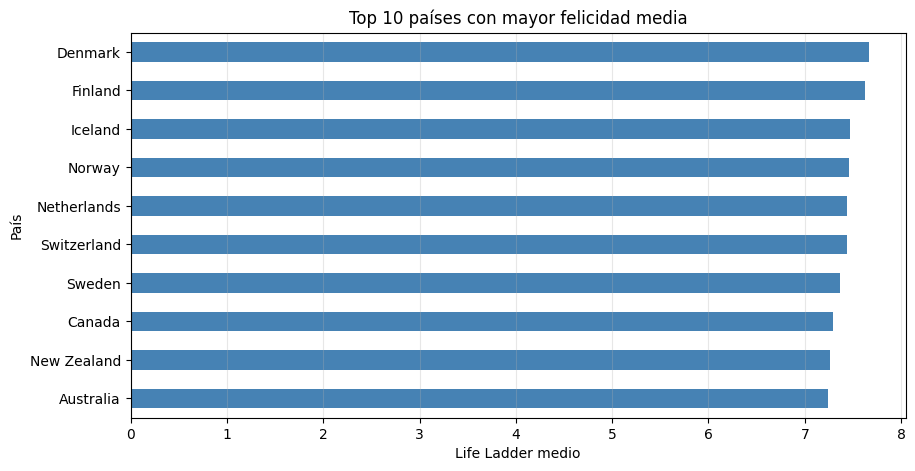

In [201]:
if "Country name" in df.columns:
    felicidad_media = df.groupby("Country name")["Life Ladder"].mean().dropna().sort_values()

    plt.figure(figsize=(10, 5))
    felicidad_media.tail(10).plot(kind="barh", color="steelblue")
    plt.title("Top 10 países con mayor felicidad media")
    plt.xlabel("Life Ladder medio")
    plt.ylabel("País")
    plt.grid(axis="x", alpha=0.3)
    plt.show()

In [202]:
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv("World_2024.csv", encoding='latin1')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2363 entries, 0 to 2362
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country name                      2363 non-null   object 
 1   year                              2363 non-null   int64  
 2   Life Ladder                       2363 non-null   float64
 3   Log GDP per capita                2335 non-null   float64
 4   Social support                    2350 non-null   float64
 5   Healthy life expectancy at birth  2300 non-null   float64
 6   Freedom to make life choices      2327 non-null   float64
 7   Generosity                        2282 non-null   float64
 8   Perceptions of corruption         2238 non-null   float64
 9   Positive affect                   2339 non-null   float64
 10  Negative affect                   2347 non-null   float64
dtypes: float64(9), int64(1), object(1)
memory usage: 203.2+ KB


«¿Cómo se relacionan la felicidad, el PIB per cápita y el apoyo social?»

Primeras cinco filas del conjunto de datos:
  Country name  year  Life Ladder  Log GDP per capita  Social support  \
0  Afghanistan  2008        3.724               7.350           0.451   
1  Afghanistan  2009        4.402               7.509           0.552   
2  Afghanistan  2010        4.758               7.614           0.539   
3  Afghanistan  2011        3.832               7.581           0.521   
4  Afghanistan  2012        3.783               7.661           0.521   

   Healthy life expectancy at birth  Freedom to make life choices  Generosity  \
0                              50.5                         0.718       0.164   
1                              50.8                         0.679       0.187   
2                              51.1                         0.600       0.118   
3                              51.4                         0.496       0.160   
4                              51.7                         0.531       0.234   

   Perceptions of corruption  

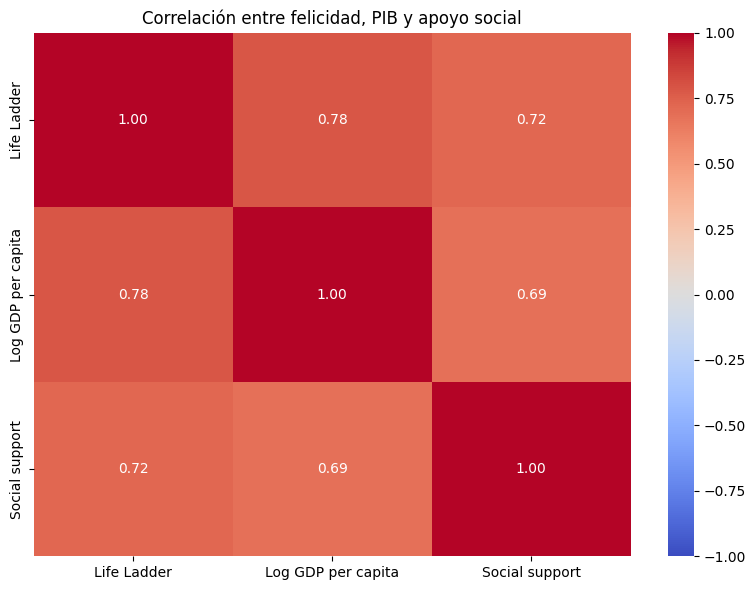

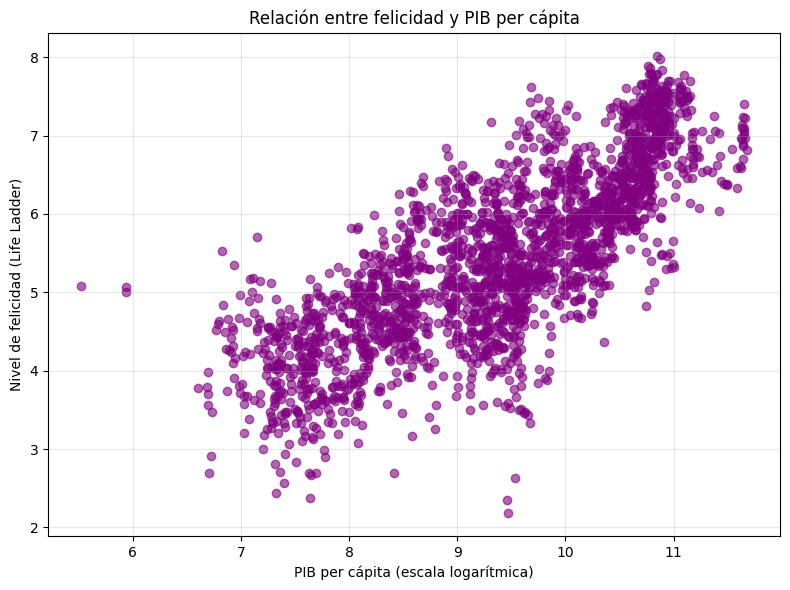

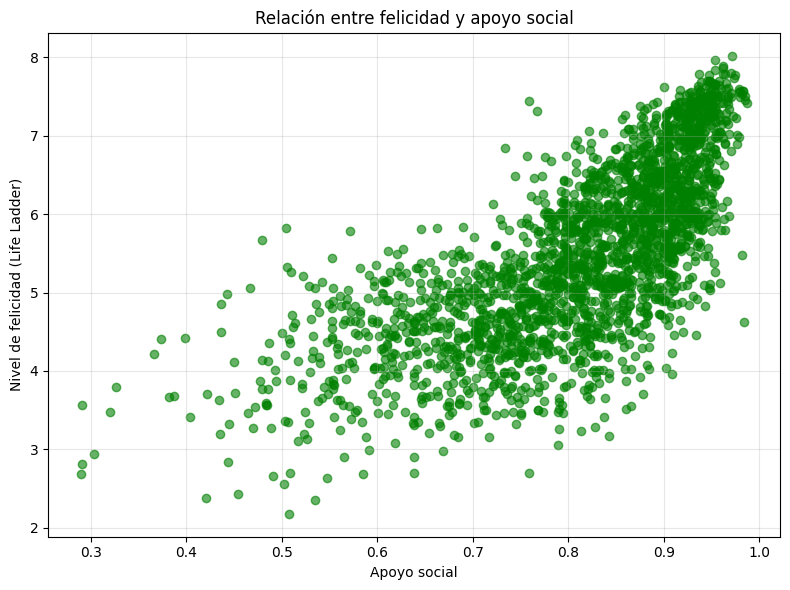


Correlaciones con el nivel de felicidad:
Felicidad y PIB per cápita: 0.783
Felicidad y apoyo social: 0.72

Cinco observaciones con mayor nivel de felicidad:
Country name  year  Life Ladder
     Denmark  2005        8.019
     Denmark  2008        7.971
     Finland  2020        7.889
     Finland  2018        7.858
     Denmark  2007        7.834

Cinco observaciones con menor nivel de felicidad:
Country name  year  Life Ladder
 Afghanistan  2022        1.281
 Afghanistan  2023        1.446
     Lebanon  2021        2.179
     Lebanon  2022        2.352
 Afghanistan  2019        2.375

Cinco países con mayor felicidad media:
Country name
Denmark        7.664
Finland        7.624
Iceland        7.468
Norway         7.464
Netherlands    7.440

Cinco países con menor felicidad media:
Country name
Rwanda                      3.654
Burundi                     3.548
Central African Republic    3.515
South Sudan                 3.402
Afghanistan                 3.220


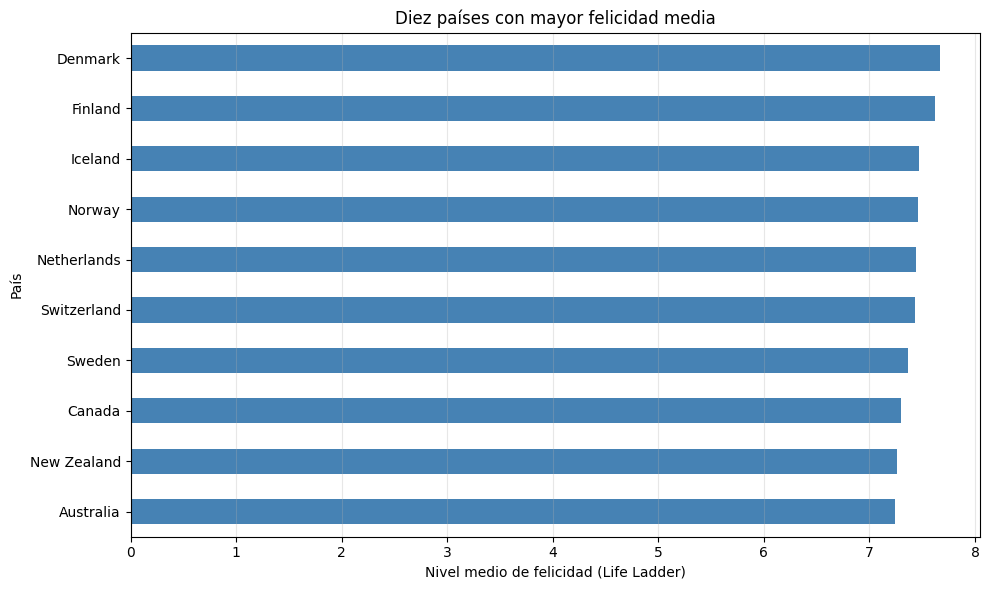

In [203]:

# ============================================================
# ANÁLISIS DE LA FELICIDAD EN EL MUNDO
# Relación entre felicidad, PIB per cápita y apoyo social
# ============================================================


# 1. Importar las bibliotecas necesarias

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# 2. Cargar el conjunto de datos

df = pd.read_csv("World_2024.csv", encoding='latin1')


# 3. Mostrar información general sobre los datos

print("Primeras cinco filas del conjunto de datos:")
print(df.head())

print("\nInformación general del conjunto de datos:")
df.info()

print("\nNombres de las columnas:")
print(df.columns.tolist())


# 4. Seleccionar las variables que vamos a analizar

variables = [
    "Life Ladder",
    "Log GDP per capita",
    "Social support"
]

# Comprobar que las columnas necesarias existen

columnas_faltantes = [
    columna for columna in variables
    if columna not in df.columns
]

if columnas_faltantes:
    raise ValueError(
        f"No se encuentran estas columnas: {columnas_faltantes}. "
        "Comprueba los nombres que aparecen en df.columns."
    )


# 5. Eliminar las filas con valores ausentes
# en las variables seleccionadas

datos = df[variables].dropna()

print("\nNúmero de observaciones originales:", len(df))
print("Número de observaciones utilizadas:", len(datos))
print("Número de filas eliminadas por valores ausentes:", len(df) - len(datos))


# 6. Calcular la matriz de correlación

correlaciones = datos.corr()

print("\nMatriz de correlación:")
print(correlaciones)


# 7. Representar la matriz de correlación
# mediante un mapa de calor

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlación entre felicidad, PIB y apoyo social")
plt.tight_layout()
plt.show()


# 8. Analizar la relación entre felicidad y PIB per cápita

plt.figure(figsize=(8, 6))

plt.scatter(
    datos["Log GDP per capita"],
    datos["Life Ladder"],
    color="purple",
    alpha=0.6
)

plt.title("Relación entre felicidad y PIB per cápita")
plt.xlabel("PIB per cápita (escala logarítmica)")
plt.ylabel("Nivel de felicidad (Life Ladder)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 9. Analizar la relación entre felicidad y apoyo social

plt.figure(figsize=(8, 6))

plt.scatter(
    datos["Social support"],
    datos["Life Ladder"],
    color="green",
    alpha=0.6
)

plt.title("Relación entre felicidad y apoyo social")
plt.xlabel("Apoyo social")
plt.ylabel("Nivel de felicidad (Life Ladder)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 10. Calcular las correlaciones con el nivel de felicidad

corr_pib = datos["Life Ladder"].corr(
    datos["Log GDP per capita"]
)

corr_apoyo = datos["Life Ladder"].corr(
    datos["Social support"]
)

print("\nCorrelaciones con el nivel de felicidad:")
print("Felicidad y PIB per cápita:", round(corr_pib, 3))
print("Felicidad y apoyo social:", round(corr_apoyo, 3))


# 11. Mostrar las cinco observaciones con mayor felicidad

datos_paises = df.dropna(subset=["Life Ladder"])

columnas_resultado = ["Country name", "Life Ladder"]

# Añadir el año si existe en el conjunto de datos

if "year" in df.columns:
    columnas_resultado.insert(1, "year")

print("\nCinco observaciones con mayor nivel de felicidad:")

print(
    datos_paises.nlargest(5, "Life Ladder")[
        columnas_resultado
    ].to_string(index=False)
)


# 12. Mostrar las cinco observaciones con menor felicidad

print("\nCinco observaciones con menor nivel de felicidad:")

print(
    datos_paises.nsmallest(5, "Life Ladder")[
        columnas_resultado
    ].to_string(index=False)
)


# 13. Calcular el nivel medio de felicidad de cada país
# a lo largo de los años disponibles, si existe la columna year

if "Country name" in df.columns:

    felicidad_media = (
        df.groupby("Country name")["Life Ladder"]
        .mean()
        .dropna()
        .sort_values(ascending=False)
    )

    print("\nCinco países con mayor felicidad media:")

    print(felicidad_media.head(5).round(3).to_string())

    print("\nCinco países con menor felicidad media:")

    print(felicidad_media.tail(5).round(3).to_string())


# 14. Representar los diez países con mayor felicidad media

if "Country name" in df.columns:

    top_10 = felicidad_media.head(10).sort_values()

    plt.figure(figsize=(10, 6))

    top_10.plot(kind="barh", color="steelblue")

    plt.title("Diez países con mayor felicidad media")
    plt.xlabel("Nivel medio de felicidad (Life Ladder)")
    plt.ylabel("País")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# FIN DEL ANÁLISIS
# ============================================================


### # 1. Importar las bibliotecas necesarias

In [204]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### # 2. Cargar el conjunto de datos

In [205]:
df = pd.read_csv("World_2024.csv", encoding='latin1')

### # 3. Mostrar información general sobre los datos

In [206]:
print("Primeras cinco filas del conjunto de datos:")
display(df.head())

print("\nInformación general del conjunto de datos:")
df.info()

print("\nNombres de las columnas:")
print(df.columns.tolist())

Primeras cinco filas del conjunto de datos:


,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.724,7.350,0.451,50.5,0.718,0.164,0.882,0.414,0.258
1,Afghanistan,2009,4.402,7.509,0.552,50.8,0.679,0.187,0.850,0.481,0.237
2,Afghanistan,2010,4.758,7.614,0.539,51.1,0.600,0.118,0.707,0.517,0.275
3,Afghanistan,2011,3.832,7.581,0.521,51.4,0.496,0.160,0.731,0.480,0.267
4,Afghanistan,2012,3.783,7.661,0.521,51.7,0.531,0.234,0.776,0.614,0.268



Información general del conjunto de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2363 entries, 0 to 2362
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country name                      2363 non-null   object 
 1   year                              2363 non-null   int64  
 2   Life Ladder                       2363 non-null   float64
 3   Log GDP per capita                2335 non-null   float64
 4   Social support                    2350 non-null   float64
 5   Healthy life expectancy at birth  2300 non-null   float64
 6   Freedom to make life choices      2327 non-null   float64
 7   Generosity                        2282 non-null   float64
 8   Perceptions of corruption         2238 non-null   float64
 9   Positive affect                   2339 non-null   float64
 10  Negative affect                   2347 non-null   float64
dtypes: float64(9), int64(1), 

### # 4. Seleccionar las variables que vamos a analizar

In [207]:
variables = [
    "Life Ladder",
    "Log GDP per capita",
    "Social support"
]

columnas_faltantes = [
    columna for columna in variables
    if columna not in df.columns
]

if columnas_faltantes:
    raise ValueError(
        f"No se encuentran estas columnas: {columnas_faltantes}. "
        "Comprueba los nombres que aparecen en df.columns."
    )

### # 5. Eliminar las filas con valores ausentes en las variables seleccionadas

In [208]:
datos = df[variables].dropna()

print("Número de observaciones originales:", len(df))
print("Número de observaciones utilizadas:", len(datos))
print("Número de filas eliminadas por valores ausentes:", len(df) - len(datos))

Número de observaciones originales: 2363
Número de observaciones utilizadas: 2322
Número de filas eliminadas por valores ausentes: 41


### # 6. Calcular la matriz de correlación

In [209]:
correlaciones = datos.corr()
print("Matriz de correlación:")
display(correlaciones)

Matriz de correlación:


,Life Ladder,Log GDP per capita,Social support
Life Ladder,1.000000,0.783036,0.719793
Log GDP per capita,0.783036,1.000000,0.685329
Social support,0.719793,0.685329,1.000000


### # 7. Representar la matriz de correlación mediante un mapa de calor

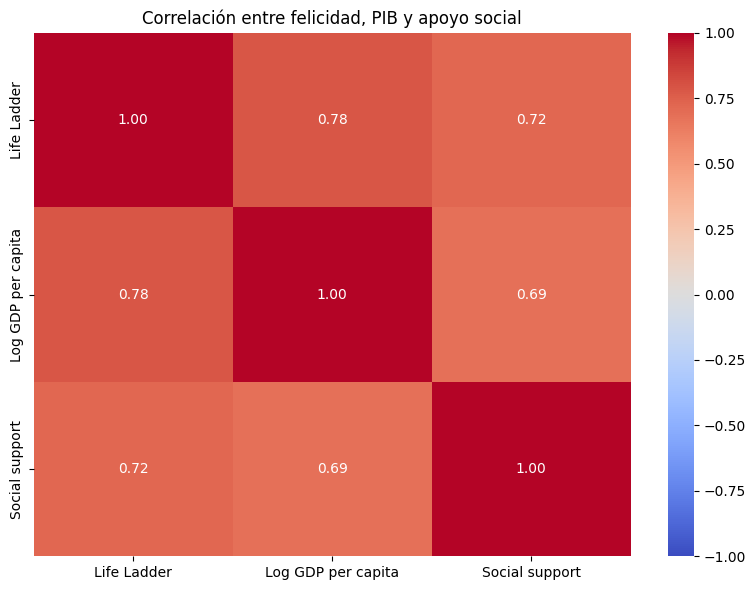

In [210]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlación entre felicidad, PIB y apoyo social")
plt.tight_layout()
plt.show()

### # 8. Analizar la relación entre felicidad y PIB per cápita

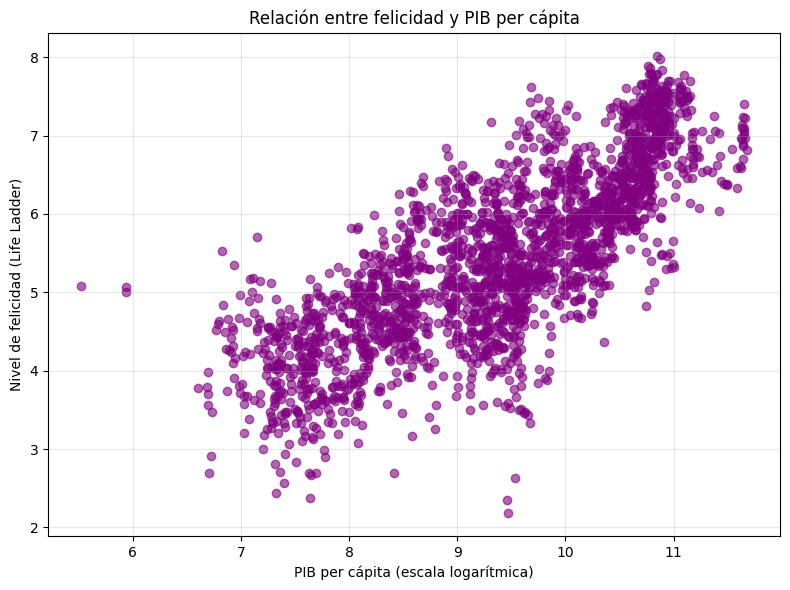

In [211]:
plt.figure(figsize=(8, 6))
plt.scatter(
    datos["Log GDP per capita"],
    datos["Life Ladder"],
    color="purple",
    alpha=0.6
)
plt.title("Relación entre felicidad y PIB per cápita")
plt.xlabel("PIB per cápita (escala logarítmica)")
plt.ylabel("Nivel de felicidad (Life Ladder)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### # 9. Analizar la relación entre felicidad y apoyo social

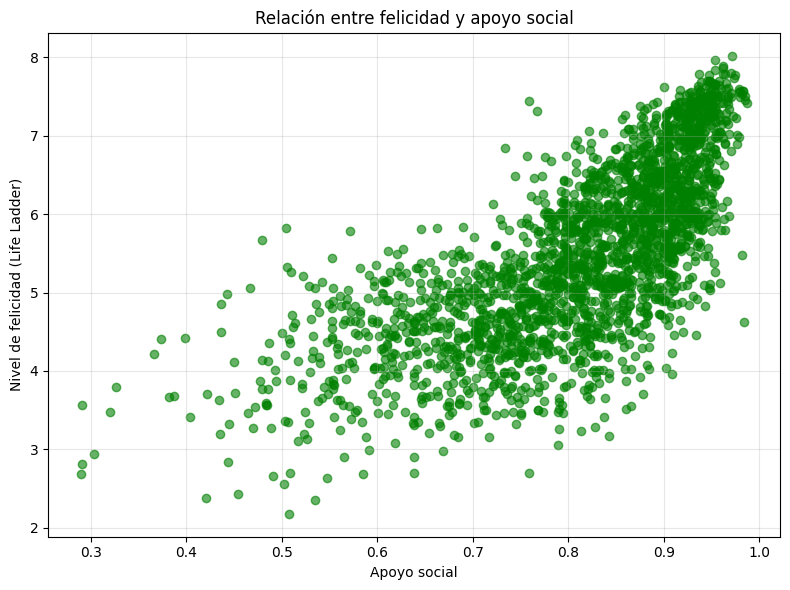

In [212]:
plt.figure(figsize=(8, 6))
plt.scatter(
    datos["Social support"],
    datos["Life Ladder"],
    color="green",
    alpha=0.6
)
plt.title("Relación entre felicidad y apoyo social")
plt.xlabel("Apoyo social")
plt.ylabel("Nivel de felicidad (Life Ladder)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### # 10. Calcular las correlaciones con el nivel de felicidad

In [213]:
corr_pib = datos["Life Ladder"].corr(datos["Log GDP per capita"])
corr_apoyo = datos["Life Ladder"].corr(datos["Social support"])

print("Correlaciones con el nivel de felicidad:")
print("Felicidad y PIB per cápita:", round(corr_pib, 3))
print("Felicidad y apoyo social:", round(corr_apoyo, 3))

Correlaciones con el nivel de felicidad:
Felicidad y PIB per cápita: 0.783
Felicidad y apoyo social: 0.72


### # 11. Mostrar las cinco observaciones con mayor felicidad

In [214]:
datos_paises = df.dropna(subset=["Life Ladder"])
columnas_resultado = ["Country name", "Life Ladder"]
if "year" in df.columns:
    columnas_resultado.insert(1, "year")

print("Cinco observaciones con mayor nivel de felicidad:")
print(datos_paises.nlargest(5, "Life Ladder")[columnas_resultado].to_string(index=False))

Cinco observaciones con mayor nivel de felicidad:
Country name  year  Life Ladder
     Denmark  2005        8.019
     Denmark  2008        7.971
     Finland  2020        7.889
     Finland  2018        7.858
     Denmark  2007        7.834


### # 12. Mostrar las cinco observaciones con menor felicidad

In [215]:
print("Cinco observaciones con menor nivel de felicidad:")
print(datos_paises.nsmallest(5, "Life Ladder")[columnas_resultado].to_string(index=False))

Cinco observaciones con menor nivel de felicidad:
Country name  year  Life Ladder
 Afghanistan  2022        1.281
 Afghanistan  2023        1.446
     Lebanon  2021        2.179
     Lebanon  2022        2.352
 Afghanistan  2019        2.375


### # 13. Calcular el nivel medio de felicidad de cada país

In [216]:
if "Country name" in df.columns:
    felicidad_media = (
        df.groupby("Country name")["Life Ladder"]
        .mean()
        .dropna()
        .sort_values(ascending=False)
    )
    print("Cinco países con mayor felicidad media:")
    print(felicidad_media.head(5).round(3).to_string())
    print("\nCinco países con menor felicidad media:")
    print(felicidad_media.tail(5).round(3).to_string())

Cinco países con mayor felicidad media:
Country name
Denmark        7.664
Finland        7.624
Iceland        7.468
Norway         7.464
Netherlands    7.440

Cinco países con menor felicidad media:
Country name
Rwanda                      3.654
Burundi                     3.548
Central African Republic    3.515
South Sudan                 3.402
Afghanistan                 3.220


### # 14. Representar los diez países con mayor felicidad media

```markdown
## Versión simplificada del análisis de datos
A continuación se presenta el código simplificado y optimizado para todo el estudio en español.
```

In [217]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carga de datos y visualización inicial
df = pd.read_csv("World_2024.csv", encoding='latin1')
display(df.head())
df.info()

,Country name,year,Life Ladder,Log GDP per capita,Social support,Healthy life expectancy at birth,Freedom to make life choices,Generosity,Perceptions of corruption,Positive affect,Negative affect
0,Afghanistan,2008,3.724,7.350,0.451,50.5,0.718,0.164,0.882,0.414,0.258
1,Afghanistan,2009,4.402,7.509,0.552,50.8,0.679,0.187,0.850,0.481,0.237
2,Afghanistan,2010,4.758,7.614,0.539,51.1,0.600,0.118,0.707,0.517,0.275
3,Afghanistan,2011,3.832,7.581,0.521,51.4,0.496,0.160,0.731,0.480,0.267
4,Afghanistan,2012,3.783,7.661,0.521,51.7,0.531,0.234,0.776,0.614,0.268


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2363 entries, 0 to 2362
Data columns (total 11 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country name                      2363 non-null   object 
 1   year                              2363 non-null   int64  
 2   Life Ladder                       2363 non-null   float64
 3   Log GDP per capita                2335 non-null   float64
 4   Social support                    2350 non-null   float64
 5   Healthy life expectancy at birth  2300 non-null   float64
 6   Freedom to make life choices      2327 non-null   float64
 7   Generosity                        2282 non-null   float64
 8   Perceptions of corruption         2238 non-null   float64
 9   Positive affect                   2339 non-null   float64
 10  Negative affect                   2347 non-null   float64
dtypes: float64(9), int64(1), object(1)
memory usage: 203.2+ KB


In [218]:
# Limpieza de datos y cálculo de correlaciones
variables = ["Life Ladder", "Log GDP per capita", "Social support"]
datos = df[variables].dropna()

correlaciones = datos.corr()
display(correlaciones)

print("\nCorrelación con el nivel de felicidad (Life Ladder):")
print(correlaciones["Life Ladder"].round(3))

,Life Ladder,Log GDP per capita,Social support
Life Ladder,1.000000,0.783036,0.719793
Log GDP per capita,0.783036,1.000000,0.685329
Social support,0.719793,0.685329,1.000000



Correlación con el nivel de felicidad (Life Ladder):
Life Ladder           1.000
Log GDP per capita    0.783
Social support        0.720
Name: Life Ladder, dtype: float64


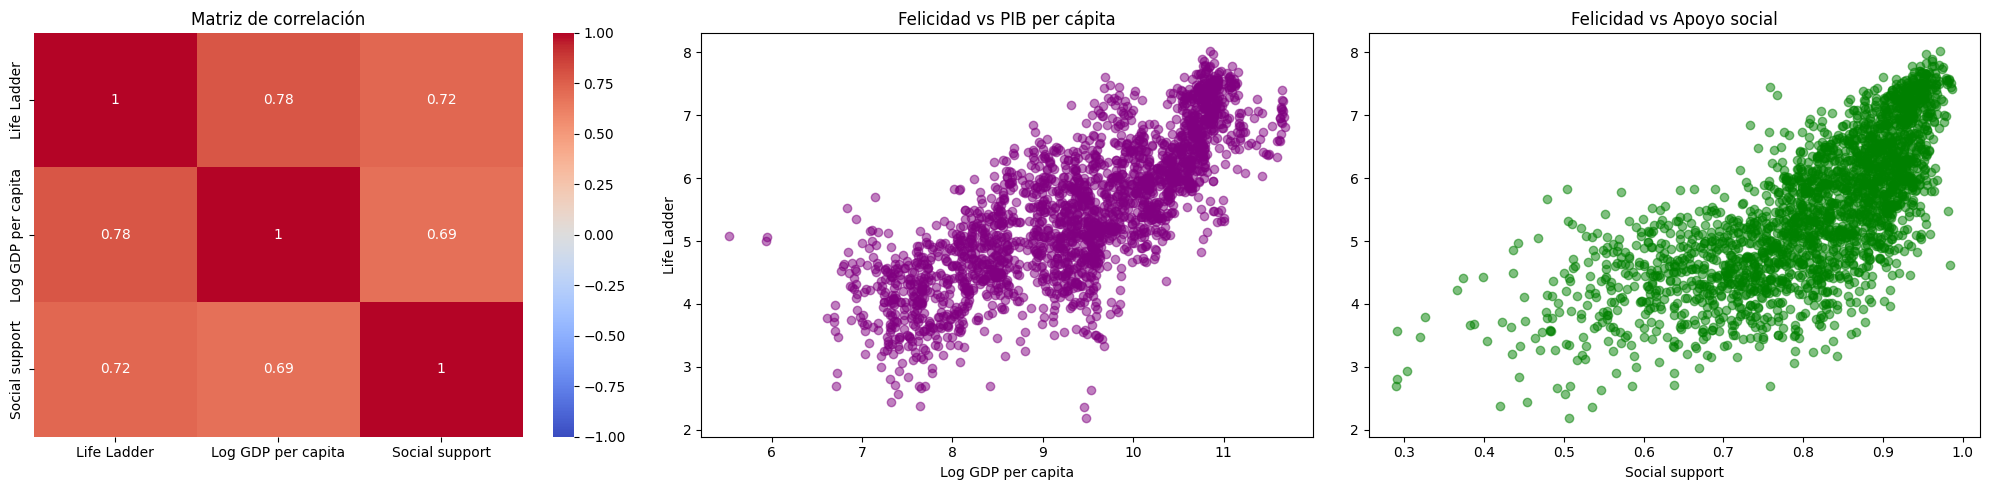

In [219]:
# Generación de gráficos para el análisis de relaciones
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Subgráfico 1: Mapa de calor de correlación
sns.heatmap(correlaciones, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Matriz de correlación")

# Subgráfico 2: Felicidad vs PIB per cápita
axes[1].scatter(datos["Log GDP per capita"], datos["Life Ladder"], color="purple", alpha=0.5)
axes[1].set_title("Felicidad vs PIB per cápita")
axes[1].set_xlabel("Log GDP per capita")
axes[1].set_ylabel("Life Ladder")

# Subgráfico 3: Felicidad vs Apoyo social
axes[2].scatter(datos["Social support"], datos["Life Ladder"], color="green", alpha=0.5)
axes[2].set_title("Felicidad vs Apoyo social")
axes[2].set_xlabel("Social support")

plt.tight_layout()
plt.show()

In [220]:
# Identificación de los valores extremos de felicidad
columnas = ["Country name", "year", "Life Ladder"] if "year" in df.columns else ["Country name", "Life Ladder"]

print("Las 5 observaciones con mayor felicidad:")
display(df.nlargest(5, "Life Ladder")[columnas])

print("\nLas 5 observaciones con menor felicidad:")
display(df.nsmallest(5, "Life Ladder")[columnas])

Las 5 observaciones con mayor felicidad:


,Country name,year,Life Ladder
539,Denmark,2005,8.019
541,Denmark,2008,7.971
677,Finland,2020,7.889
675,Finland,2018,7.858
540,Denmark,2007,7.834



Las 5 observaciones con menor felicidad:


,Country name,year,Life Ladder
13,Afghanistan,2022,1.281
14,Afghanistan,2023,1.446
1192,Lebanon,2021,2.179
1193,Lebanon,2022,2.352
11,Afghanistan,2019,2.375


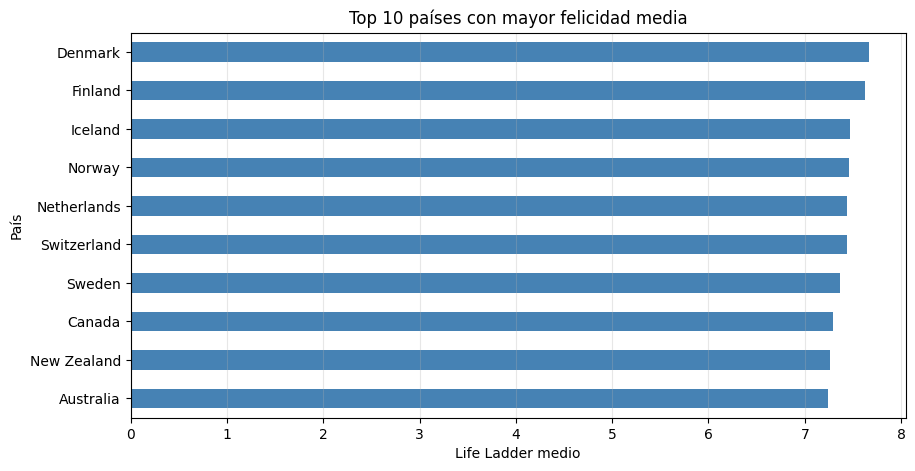

In [221]:
# Agrupación por país y gráfico de barras para el Top 10
if "Country name" in df.columns:
    felicidad_media = df.groupby("Country name")["Life Ladder"].mean().dropna().sort_values()

    plt.figure(figsize=(10, 5))
    felicidad_media.tail(10).plot(kind="barh", color="steelblue")
    plt.title("Top 10 países con mayor felicidad media")
    plt.xlabel("Life Ladder medio")
    plt.ylabel("País")
    plt.grid(axis="x", alpha=0.3)
    plt.show()

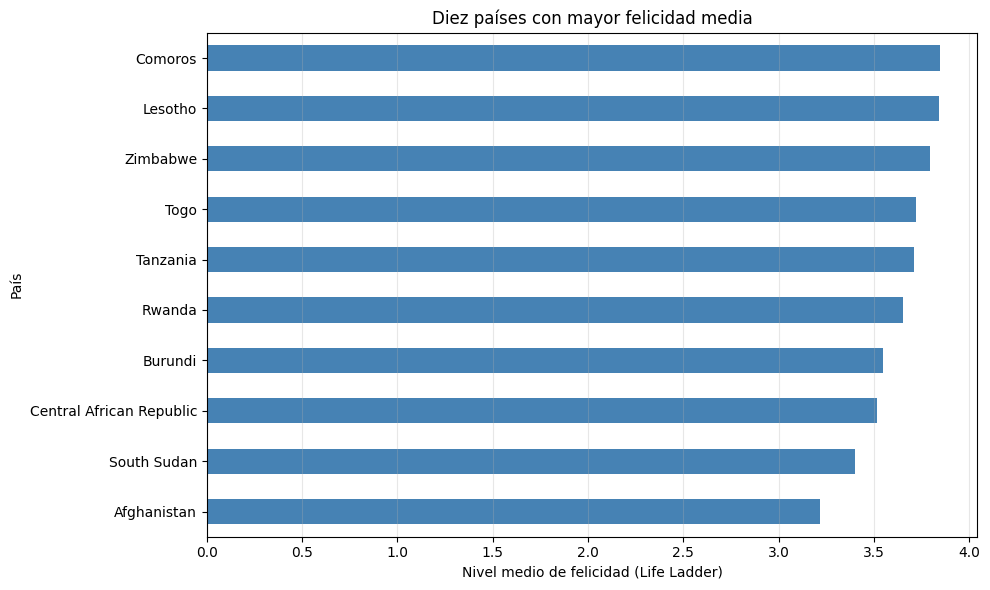

In [222]:
if "Country name" in df.columns:
    top_10 = felicidad_media.head(10).sort_values()
    plt.figure(figsize=(10, 6))
    top_10.plot(kind="barh", color="steelblue")
    plt.title("Diez países con mayor felicidad media")
    plt.xlabel("Nivel medio de felicidad (Life Ladder)")
    plt.ylabel("País")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

Primeras cinco filas del conjunto de datos:
  Country name  year  Life Ladder  Log GDP per capita  Social support  \
0  Afghanistan  2008        3.724               7.350           0.451   
1  Afghanistan  2009        4.402               7.509           0.552   
2  Afghanistan  2010        4.758               7.614           0.539   
3  Afghanistan  2011        3.832               7.581           0.521   
4  Afghanistan  2012        3.783               7.661           0.521   

   Healthy life expectancy at birth  Freedom to make life choices  Generosity  \
0                              50.5                         0.718       0.164   
1                              50.8                         0.679       0.187   
2                              51.1                         0.600       0.118   
3                              51.4                         0.496       0.160   
4                              51.7                         0.531       0.234   

   Perceptions of corruption  

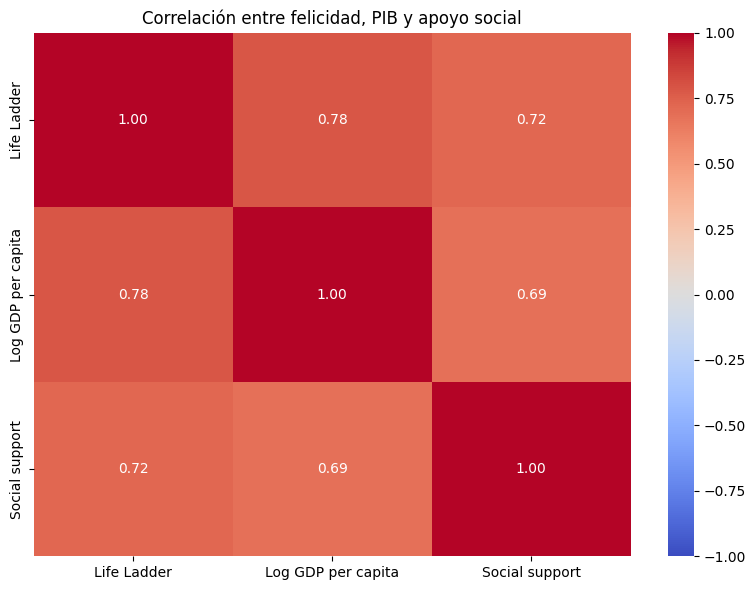

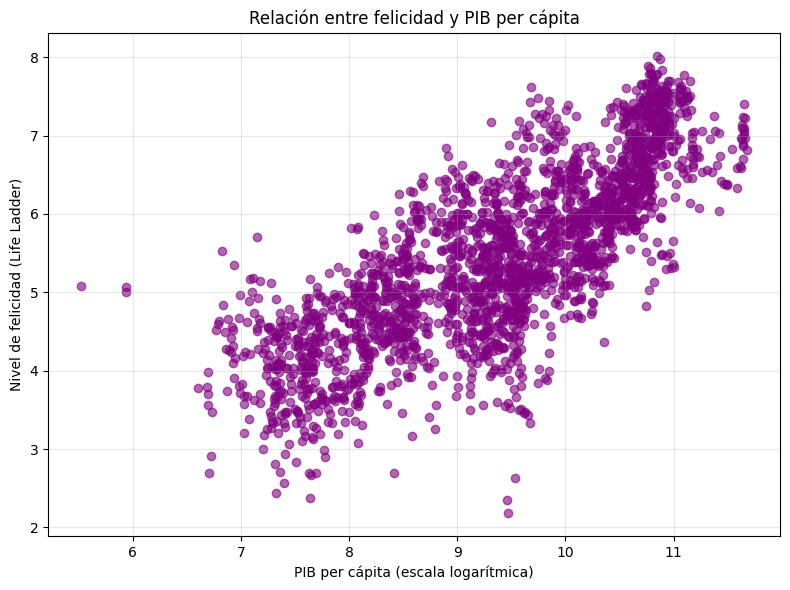

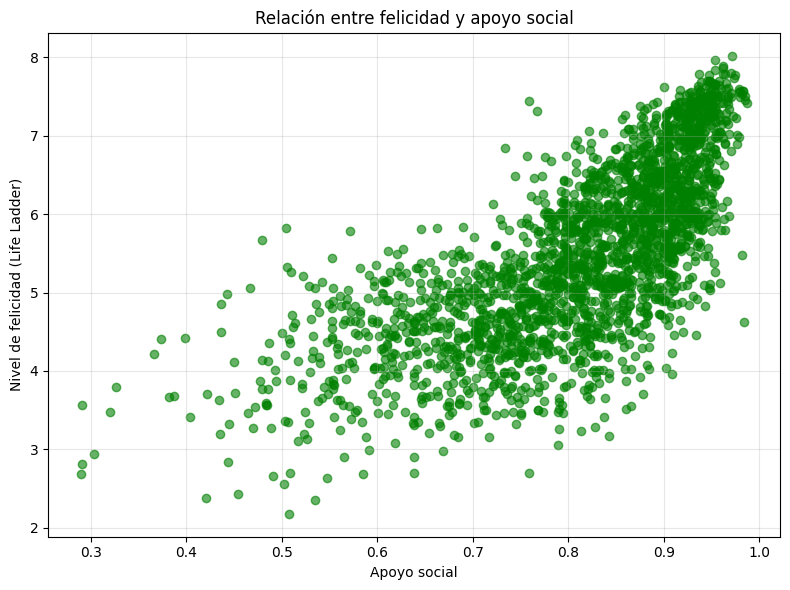


Correlaciones con el nivel de felicidad:
Felicidad y PIB per cápita: 0.783
Felicidad y apoyo social: 0.72

Cinco observaciones con mayor nivel de felicidad:
Country name  year  Life Ladder
     Denmark  2005        8.019
     Denmark  2008        7.971
     Finland  2020        7.889
     Finland  2018        7.858
     Denmark  2007        7.834

Cinco observaciones con menor nivel de felicidad:
Country name  year  Life Ladder
 Afghanistan  2022        1.281
 Afghanistan  2023        1.446
     Lebanon  2021        2.179
     Lebanon  2022        2.352
 Afghanistan  2019        2.375

Cinco países con mayor felicidad media:
Country name
Denmark        7.664
Finland        7.624
Iceland        7.468
Norway         7.464
Netherlands    7.440

Cinco países con menor felicidad media:
Country name
Rwanda                      3.654
Burundi                     3.548
Central African Republic    3.515
South Sudan                 3.402
Afghanistan                 3.220


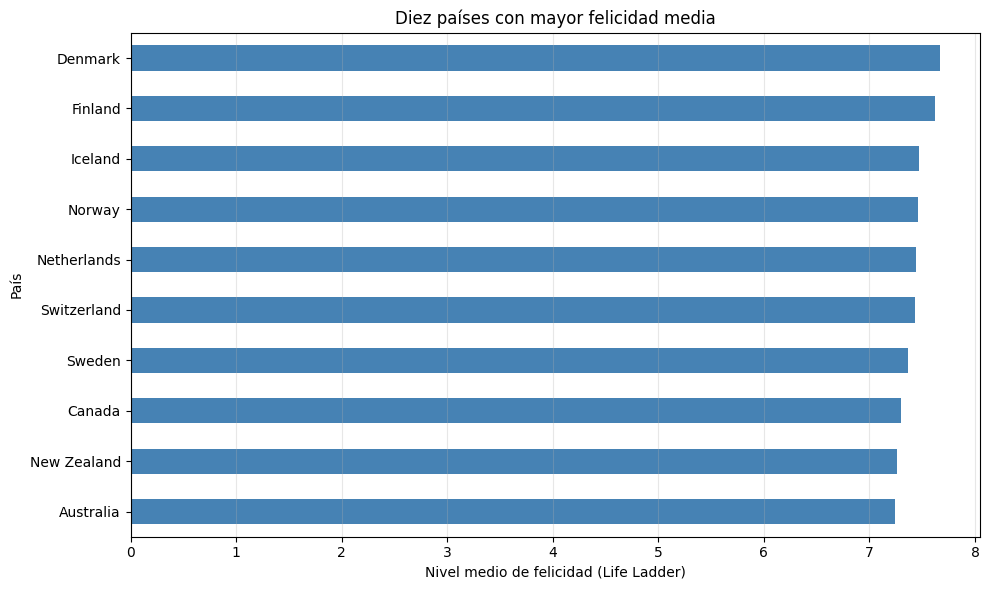

In [223]:

# ============================================================
# ANÁLISIS DE LA FELICIDAD EN EL MUNDO
# Relación entre felicidad, PIB per cápita y apoyo social
# ============================================================


# 1. Importar las bibliotecas necesarias

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# 2. Cargar el conjunto de datos

df = pd.read_csv("World_2024.csv", encoding='latin1')


# 3. Mostrar información general sobre los datos

print("Primeras cinco filas del conjunto de datos:")
print(df.head())

print("\nInformación general del conjunto de datos:")
df.info()

print("\nNombres de las columnas:")
print(df.columns.tolist())


# 4. Seleccionar las variables que vamos a analizar

variables = [
    "Life Ladder",
    "Log GDP per capita",
    "Social support"
]

# Comprobar que las columnas necesarias existen

columnas_faltantes = [
    columna for columna in variables
    if columna not in df.columns
]

if columnas_faltantes:
    raise ValueError(
        f"No se encuentran estas columnas: {columnas_faltantes}. "
        "Comprueba los nombres que aparecen en df.columns."
    )


# 5. Eliminar las filas con valores ausentes
# en las variables seleccionadas

datos = df[variables].dropna()

print("\nNúmero de observaciones originales:", len(df))
print("Número de observaciones utilizadas:", len(datos))
print("Número de filas eliminadas por valores ausentes:", len(df) - len(datos))


# 6. Calcular la matriz de correlación

correlaciones = datos.corr()

print("\nMatriz de correlación:")
print(correlaciones)


# 7. Representar la matriz de correlación
# mediante un mapa de calor

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlación entre felicidad, PIB y apoyo social")
plt.tight_layout()
plt.show()


# 8. Analizar la relación entre felicidad y PIB per cápita

plt.figure(figsize=(8, 6))

plt.scatter(
    datos["Log GDP per capita"],
    datos["Life Ladder"],
    color="purple",
    alpha=0.6
)

plt.title("Relación entre felicidad y PIB per cápita")
plt.xlabel("PIB per cápita (escala logarítmica)")
plt.ylabel("Nivel de felicidad (Life Ladder)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 9. Analizar la relación entre felicidad y apoyo social

plt.figure(figsize=(8, 6))

plt.scatter(
    datos["Social support"],
    datos["Life Ladder"],
    color="green",
    alpha=0.6
)

plt.title("Relación entre felicidad y apoyo social")
plt.xlabel("Apoyo social")
plt.ylabel("Nivel de felicidad (Life Ladder)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 10. Calcular las correlaciones con el nivel de felicidad

corr_pib = datos["Life Ladder"].corr(
    datos["Log GDP per capita"]
)

corr_apoyo = datos["Life Ladder"].corr(
    datos["Social support"]
)

print("\nCorrelaciones con el nivel de felicidad:")
print("Felicidad y PIB per cápita:", round(corr_pib, 3))
print("Felicidad y apoyo social:", round(corr_apoyo, 3))


# 11. Mostrar las cinco observaciones con mayor felicidad

datos_paises = df.dropna(subset=["Life Ladder"])

columnas_resultado = ["Country name", "Life Ladder"]

# Añadir el año si existe en el conjunto de datos

if "year" in df.columns:
    columnas_resultado.insert(1, "year")

print("\nCinco observaciones con mayor nivel de felicidad:")

print(
    datos_paises.nlargest(5, "Life Ladder")[
        columnas_resultado
    ].to_string(index=False)
)


# 12. Mostrar las cinco observaciones con menor felicidad

print("\nCinco observaciones con menor nivel de felicidad:")

print(
    datos_paises.nsmallest(5, "Life Ladder")[
        columnas_resultado
    ].to_string(index=False)
)


# 13. Calcular el nivel medio de felicidad de cada país
# a lo largo de los años disponibles, si existe la columna year

if "Country name" in df.columns:

    felicidad_media = (
        df.groupby("Country name")["Life Ladder"]
        .mean()
        .dropna()
        .sort_values(ascending=False)
    )

    print("\nCinco países con mayor felicidad media:")

    print(felicidad_media.head(5).round(3).to_string())

    print("\nCinco países con menor felicidad media:")

    print(felicidad_media.tail(5).round(3).to_string())


# 14. Representar los diez países con mayor felicidad media

if "Country name" in df.columns:

    top_10 = felicidad_media.head(10).sort_values()

    plt.figure(figsize=(10, 6))

    top_10.plot(kind="barh", color="steelblue")

    plt.title("Diez países con mayor felicidad media")
    plt.xlabel("Nivel medio de felicidad (Life Ladder)")
    plt.ylabel("País")
    plt.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# FIN DEL ANÁLISIS
# ============================================================


In [224]:
import pandas as pd
import plotly.express as px

# 1. Cargar los datos
df = pd.read_csv("World_2024.csv", encoding="latin1")

# 2. Comprobar los nombres de las columnas
print(df.columns.tolist())

# 3. Seleccionar las columnas necesarias
datos = df[["Country name", "Life Ladder"]].dropna()

# 4. Calcular la felicidad media de cada país
felicidad = (
    datos.groupby("Country name", as_index=False)["Life Ladder"]
    .mean()
)

# 5. Crear el mapa mundial
fig = px.choropleth(
    felicidad,
    locations="Country name",
    locationmode="country names",
    color="Life Ladder",
    hover_name="Country name",
    color_continuous_scale="Viridis",
    labels={
        "Life Ladder": "Nivel de felicidad"
    },
    title="Mapa mundial de la felicidad"
)

# 6. Personalizar el diseño
fig.update_layout(
    title_x=0.5,
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type="natural earth"
    )
)

# 7. Mostrar el mapa interactivo
fig.show()


['Country name', 'year', 'Life Ladder', 'Log GDP per capita', 'Social support', 'Healthy life expectancy at birth', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'Positive affect', 'Negative affect']


### # 15. Visualización del mapa de felicidad global interactivo

Para comprender mejor la distribución geográfica del bienestar en el mundo, crearemos un mapa interactivo (coroplético) utilizando la biblioteca `plotly.express`. Este mapa agrupa los datos históricos por país, calcula el nivel de felicidad medio (`Life Ladder`) y lo proyecta sobre un mapa global, facilitando la identificación visual de patrones regionales de bienestar.

In [225]:
import pandas as pd
import plotly.express as px

# Cargar los datos y eliminar valores nulos en el nivel de felicidad
datos_mapa = df[["Country name", "Life Ladder"]].dropna()

# Calcular el promedio histórico de felicidad para cada país
felicidad_pais = datos_mapa.groupby("Country name", as_index=False)["Life Ladder"].mean()

# Crear el mapa coroplético mundial
fig_mapa = px.choropleth(
    felicidad_pais,
    locations="Country name",
    locationmode="country names",
    color="Life Ladder",
    hover_name="Country name",
    color_continuous_scale="Viridis",
    labels={"Life Ladder": "Felicidad Promedio"},
    title="Mapa Mundial del Nivel de Felicidad (Promedio Histórico)"
)

# Personalizar la visualización y proyección del mapa
fig_mapa.update_layout(
    title_x=0.5,
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type="natural earth"
    )
)

# Mostrar el mapa interactivo en una ventana de resultados separada
fig_mapa.show()

In [226]:
%pip install cairosvg

Introduce el nombre de un país (por ejemplo, Spain): Argentina

Evolución de la felicidad en Argentina:


Country name,year,Life Ladder
Argentina,2006,6.313000
Argentina,2007,6.073000
Argentina,2008,5.961000
Argentina,2009,6.424000
Argentina,2010,6.441000
Argentina,2011,6.776000
Argentina,2012,6.468000
Argentina,2013,6.582000
Argentina,2014,6.671000
Argentina,2015,6.697000


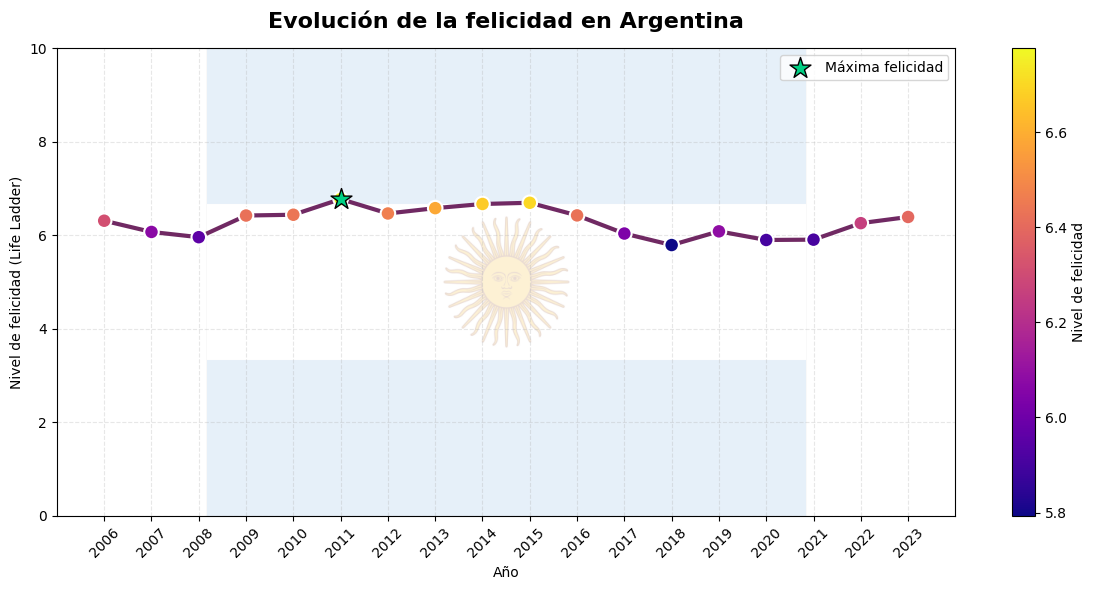

In [229]:

# Si es necesario, instala la biblioteca:
%pip install pycountry

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pycountry
from urllib.request import urlopen
from io import BytesIO

# Cargar los datos
df = pd.read_csv("World_2024.csv", encoding="latin1")

# Pedir el nombre del país
pais = input(
    "Introduce el nombre de un país (por ejemplo, Spain): "
).strip()

# Buscar los datos del país
datos_pais = df[
    df["Country name"].str.casefold() == pais.casefold()
].copy()

if datos_pais.empty:
    print("No se han encontrado datos para ese país.")

else:
    datos_pais = datos_pais.dropna(
        subset=["year", "Life Ladder"]
    ).sort_values("year")

    if datos_pais.empty:
        print("No hay datos disponibles para ese país.")

    else:
        print(f"\nEvolución de la felicidad en {pais}:")

        # Mostrar la tabla sin el índice
        display(
            datos_pais[["Country name", "year", "Life Ladder"]]
            .style.hide(axis="index")
        )

        # Buscar el código internacional del país
        try:
            pais_iso = pycountry.countries.lookup(pais)
            codigo = pais_iso.alpha_2.lower()

            # Descargar la imagen de la bandera
            url = (
                "https://raw.githubusercontent.com/"
                "amckenna41/iso3166-flags/main/"
                f"iso3166-1-flags/{codigo}.svg"
            )

            # Crear el gráfico
            fig, ax = plt.subplots(figsize=(12, 6))

            # Dibujar el fondo blanco inicialmente
            ax.set_facecolor("white")

            # Dibujar la línea de felicidad
            ax.plot(
                datos_pais["year"],
                datos_pais["Life Ladder"],
                color="#702963",
                linewidth=3,
                zorder=3
            )

            # Añadir puntos de colores
            puntos = ax.scatter(
                datos_pais["year"],
                datos_pais["Life Ladder"],
                c=datos_pais["Life Ladder"],
                cmap="plasma",
                s=110,
                edgecolors="white",
                linewidths=1.5,
                zorder=4
            )

            # Destacar el año con mayor felicidad
            mejor = datos_pais.loc[
                datos_pais["Life Ladder"].idxmax()
            ]

            ax.scatter(
                mejor["year"],
                mejor["Life Ladder"],
                color="#00D084",
                s=250,
                marker="*",
                edgecolors="black",
                zorder=5,
                label="Máxima felicidad"
            )

            # Añadir títulos y etiquetas
            ax.set_title(
                f"Evolución de la felicidad en {pais}",
                fontsize=16,
                fontweight="bold",
                pad=15
            )
            ax.set_xlabel("Año")
            ax.set_ylabel("Nivel de felicidad (Life Ladder)")
            ax.set_ylim(0, 10)
            ax.set_xticks(sorted(datos_pais["year"].unique()))
            plt.xticks(rotation=45)
            ax.grid(True, linestyle="--", alpha=0.3)
            ax.legend()

            # Mostrar la escala de colores
            fig.colorbar(
                puntos,
                ax=ax,
                label="Nivel de felicidad"
            )

            # Descargar y colocar la bandera como fondo
            try:
                import cairosvg

                contenido = urlopen(url, timeout=10).read()
                png = cairosvg.svg2png(
                    bytestring=contenido,
                    output_width=1200,
                    output_height=600
                )
                imagen = mpimg.imread(BytesIO(png), format="png")

                ax.imshow(
                    imagen,
                    extent=[
                        datos_pais["year"].min() - 1,
                        datos_pais["year"].max() + 1,
                        0,
                        10
                    ],
                    aspect="auto",
                    alpha=0.18,
                    zorder=1
                )

                # Mantener las líneas y los puntos por encima del fondo
                ax.set_xlim(
                    datos_pais["year"].min() - 1,
                    datos_pais["year"].max() + 1
                )

            except Exception as error:
                print(
                    "No se pudo cargar la bandera; "
                    "se mostrará el gráfico sin ella."
                )
                print("Detalle:", error)

            plt.tight_layout()
            plt.show()

        except LookupError:
            print(
                "No se encontró el código internacional del país. "
                "Prueba con el nombre en inglés usado en el CSV."
            )
